# INR reconstruction from even/odd tilt-series

Fit an implicit neural representation of the 3D density to the simulated ribosome tilt-series
(`Simulation_forward_full.ipynb`).

* **Rendering**: one ray per detector pixel, the network is integrated along the ray (real space, no Fourier slice).
* **Forward model**: the rendered tilt images are multiplied with the same |CTF| x dose weighting x cos(tilt) filter
  as the simulation, so the network learns the actual (positive) potential.
* **Priors**: positivity (softplus output) and an L1 second-order total-variation penalty on the rendered density
  (sparse curvature: smooth, no hard edges). Both are nonlinear, so the measured frequencies constrain the missing
  wedge, which the projections alone never do.
* **Gold standard**: one INR per half. The other half has independent noise and is used for validation:
  $\mathbb{E}\|Pf - y_{odd}\|^2 = \|Pf - y_{clean}\|^2 + \sigma^2$ as long as $f$ never saw the odd noise, so the
  checkpoint with the lowest validation loss is the one closest to the clean data. The validation loss was also used
  to choose the TV weight (see the notes at the end).

In [1]:
from pathlib import Path
import copy
import time

import matplotlib.pyplot as plt
import mrcfile
import numpy as np
import torch
import torch.nn.functional as F
from torch_ctf import calculate_ctf_2d
from torch_fourier_filter.dose_weight import dose_weight_2d
from torch_fourier_shell_correlation import fourier_shell_correlation
from torch_fourier_slice import backproject_2d_to_3d, project_3d_to_2d
from torch_grid_utils import fftfreq_grid
from torch_affine_utils.transforms_3d import Ry

DATA = Path("data")
CACHE = Path.home() / ".cache" / "arp"
PIXEL_SPACING = 5.0
VOLTAGE = 300
BOX = 96
CENTER = BOX // 2  # rotation centre in pixels, same as the Fourier-slice convention
DOSE = [
    82.2, 79.8, 70.68, 68.4, 66.12, 54.72, 52.44, 50.16, 47.88, 41.04, 38.76, 31.92,
    29.64, 22.8, 20.52, 13.68, 11.4, 4.56, 2.28, 0, 6.84, 9.12,
    15.96, 18.24, 25.08, 27.36, 34.2, 36.48, 43.32, 45.6, 57, 59.28,
    61.559998, 63.84, 72.96, 75.24, 77.52
]  # same accumulated dose as the simulation

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print(device)

mps


## Load the tilt-series and the ground truth (ground truth is only used for evaluation)

In [2]:
even = torch.tensor(mrcfile.read(DATA / "ribosome_tiltseries_even.mrc"))
odd = torch.tensor(mrcfile.read(DATA / "ribosome_tiltseries_odd.mrc"))
clean = torch.tensor(mrcfile.read(DATA / "ribosome_tiltseries_clean.mrc"))
tilt_angles = torch.tensor(np.loadtxt(DATA / "ribosome_tiltseries.tlt"), dtype=torch.float32)
ground_truth = torch.load(CACHE / f"4v6x_box{BOX}_{PIXEL_SPACING:g}apx_peng.pt").float()
m_projection = Ry(tilt_angles)[..., :3, :3].float()
print(even.shape, tilt_angles.shape, ground_truth.shape)

torch.Size([37, 96, 96]) torch.Size([37]) torch.Size([96, 96, 96])


## Microscope filter

Same as the simulation: phase-flipped CTF (|CTF|), dose weighting and cos(tilt) dampening, one 2D filter per tilt.

In [3]:
ctf_image = calculate_ctf_2d(
    defocus=3,
    astigmatism=0.0,
    astigmatism_angle=0.0,
    voltage=VOLTAGE,
    spherical_aberration=2.7,
    amplitude_contrast=0.07,
    phase_shift=0.0,
    pixel_size=PIXEL_SPACING,
    image_shape=(BOX, BOX),
    rfft=True,
    fftshift=False,
)
frequency_grid = fftfreq_grid(image_shape=(BOX, BOX), rfft=True, fftshift=False, norm=True)
ctf_image[frequency_grid > 0.5] = 0
ctf_per_tilt = dose_weight_2d(
    image_dft=torch.abs(ctf_image).repeat(len(DOSE), 1, 1),  # phase-flipped data: |CTF|
    image_shape=(BOX, BOX),
    pixel_size=PIXEL_SPACING,
    dose=torch.tensor(DOSE),
    voltage=VOLTAGE,
)
ctf_per_tilt *= torch.cos(torch.deg2rad(tilt_angles))[:, None, None]

## Ray geometry

Detector pixel $(x, y)$ of a tilt with rotation $R$ (xyz convention, as used by the simulation) sees the line
$p(t) = R\,(x, y, t)^T$ through the volume, with coordinates in voxels relative to the centre. Each ray is clipped to
the reconstruction box (slab test) and sampled at `n_samples` points; during training the samples are jittered
within their interval (stratified sampling) so the network is queried at continuous positions.

In [4]:
BOX_LOW, BOX_HIGH = -CENTER - 0.5, CENTER - 0.5  # outer edges of the voxel grid


def ray_samples(rotations, y, x, n_samples, jitter):
    """Sample points (xyz, voxel units) along the rays of detector pixels (y, x)."""
    origin = rotations[..., :, 0] * x[:, None] + rotations[..., :, 1] * y[:, None]  # R (x, y, 0)
    direction = rotations[..., :, 2]  # R (0, 0, 1)
    safe_direction = torch.where(direction.abs() < 1e-6, torch.full_like(direction, 1e-6), direction)
    t1 = (BOX_LOW - origin) / safe_direction
    t2 = (BOX_HIGH - origin) / safe_direction
    t_near = torch.minimum(t1, t2).amax(dim=-1)
    t_far = torch.maximum(t1, t2).amin(dim=-1)
    length = (t_far - t_near).clamp(min=0)

    u = (torch.arange(n_samples, device=x.device) + 0.5) / n_samples
    u = u.expand(len(x), n_samples)
    if jitter:
        u = u + (torch.rand_like(u) - 0.5) / n_samples
    t = t_near[:, None] + u * length[:, None]
    points = origin[:, None, :] + t[..., None] * direction[:, None, :]
    return points, length / n_samples

Sanity check of the geometry: ray-trace the ground-truth voxel volume (trilinear lookup, only for this check) and
compare it with the Fourier-slice projections used in the simulation.

In [5]:
detector_1d = torch.arange(BOX) - CENTER
detector_y, detector_x = [a.flatten().float() for a in torch.meshgrid(detector_1d, detector_1d, indexing="ij")]


def ray_trace_voxels(volume, rotation, n_samples=192):
    points, dt = ray_samples(rotation.expand(len(detector_x), 3, 3), detector_y, detector_x, n_samples, jitter=False)
    grid = (points + CENTER) / (BOX - 1) * 2 - 1  # grid_sample expects (x, y, z) in [-1, 1]
    values = F.grid_sample(volume[None, None], grid[None, None], align_corners=True)[0, 0, 0]
    return (values.sum(dim=-1) * dt).reshape(BOX, BOX)


def correlation(a, b):
    a = a.flatten() - a.mean()
    b = b.flatten() - b.mean()
    return (a @ b / (a.norm() * b.norm())).item()


fourier_projections = project_3d_to_2d(ground_truth, m_projection)
for i in [0, len(tilt_angles) // 2, len(tilt_angles) - 1]:
    traced = ray_trace_voxels(ground_truth, m_projection[i])
    print(f"tilt {tilt_angles[i]:+.0f}: cc ray-traced vs Fourier-slice = {correlation(traced, fourier_projections[i]):.4f}")

tilt -54: cc ray-traced vs Fourier-slice = 0.9992
tilt +0: cc ray-traced vs Fourier-slice = 0.9999
tilt +54: cc ray-traced vs Fourier-slice = 0.9991


## Metrics and FBP baseline

* FSC against the ground truth, split into the **measured** region of Fourier space and the **missing wedge**. The
  tilt axis is y, so a Fourier voxel is in the wedge when its direction in the kx-kz plane lies beyond the maximum
  tilt angle (plus a 3 degree margin for the tilt sampling).
* CC against the ground truth and against the ground truth smoothed with a Gaussian of sigma 8 A (roughly what is
  recoverable here, ~25 A).
* Background/particle std: fluctuation outside a blurred ground-truth mask relative to inside it (lower is flatter).

In [6]:
# shell i has spatial frequency i / (BOX * PIXEL_SPACING) 1/A
shell_frequency = torch.arange(BOX // 2 + 1) / (BOX * PIXEL_SPACING)
kz = torch.fft.fftfreq(BOX)[:, None, None]
ky = torch.fft.fftfreq(BOX)[None, :, None]
kx = torch.fft.rfftfreq(BOX)[None, None, :]
rfft_shape = (BOX, BOX, BOX // 2 + 1)
shell = torch.round(torch.sqrt(kz ** 2 + ky ** 2 + kx ** 2) * BOX).long().expand(rfft_shape)
kxz_angle = torch.rad2deg(torch.atan2(kz.abs(), kx.abs())).expand(rfft_shape)
in_wedge = kxz_angle > tilt_angles.abs().max() + 3


def fsc(volume, reference=ground_truth, region=None):
    """FSC per shell, optionally restricted to a region of Fourier space."""
    a = torch.fft.rfftn(volume.detach().cpu().float())
    b = torch.fft.rfftn(reference.float())
    region = torch.ones(rfft_shape, dtype=torch.bool) if region is None else region
    curve = torch.full((BOX // 2 + 1,), float("nan"))
    for s in range(BOX // 2 + 1):
        selection = (shell == s) & region
        if selection.any():
            numerator = (a[selection] * b[selection].conj()).real.sum()
            denominator = torch.sqrt((a[selection].abs() ** 2).sum() * (b[selection].abs() ** 2).sum())
            curve[s] = numerator / denominator
    return curve


def gaussian_lowpass(volume, sigma):
    """Gaussian smoothing with a real-space standard deviation sigma in A."""
    k_squared = (kz ** 2 + ky ** 2 + kx ** 2) / PIXEL_SPACING ** 2  # (1/A)^2
    return torch.fft.irfftn(
        torch.fft.rfftn(volume) * torch.exp(-2 * torch.pi ** 2 * sigma ** 2 * k_squared), s=(BOX, BOX, BOX)
    )


truth_lowpass = gaussian_lowpass(ground_truth, sigma=8.0)
blurred_truth = gaussian_lowpass(ground_truth, sigma=6.4)
background = blurred_truth < 0.01 * blurred_truth.max()


def background_ratio(volume):
    return (volume[background].std() / volume[~background].std()).item()


fbp_full = backproject_2d_to_3d((even + odd) / 2, m_projection, pad_factor=3.0)
fbp_power = torch.fft.rfftn(fbp_full).abs() ** 2
print("FBP power inside / outside wedge:", (fbp_power[in_wedge].mean() / fbp_power[~in_wedge].mean()).item())
print("FBP even+odd cc:", correlation(fbp_full, ground_truth))

FBP power inside / outside wedge: 0.0203769039362669
FBP even+odd cc: 0.17160287499427795


## INR

Multi-resolution feature grid encoding (Instant-NGP style, dense instead of hashed since the volume is small):
each level is a learnable grid of feature vectors spanning the box, a coordinate gathers trilinearly interpolated
features from every level and a small MLP maps the concatenation to a density. The encoding is local, so fitting
noise in one region does not create ripples elsewhere. Six levels (8 to 48 cells across the box) with 2 features per
node give ~390k parameters, about 0.44 per voxel; the 48-cell level is needed for the detail in the second CTF lobe,
while 2 instead of 4 features per node costs almost nothing. 

**Smoothstep interpolation**: plain trilinear interpolation is continuous but its slope jumps at every cell boundary,
and these kinks show up as fine grid-aligned stripes in the density. Within each cell the interpolation weight $t$ is
replaced by $3t^2 - 2t^3$ (as in Instant-NGP's smoothstep option), which makes the slope continuous. It is implemented
by mapping the coordinate to cell index + smoothstep(position in cell) before the trilinear lookup.

**Random grid offsets**: each level is shifted by a random sub-cell offset (fixed per model, so different for the two
halves). Any remaining grid-aligned pattern (smoothstep has zero slope at the nodes) then does not line up between the
halves and does not inflate the half-map FSC.

**Positivity**: the MLP output goes through a sharp softplus ($\beta = 20$), with the last bias initialised negative so
the volume starts close to zero.

**Second-order TV**: L1 norm of the Hessian (Frobenius norm per point) of the rendered density, estimated at random
continuous points anywhere in the box, up to the faces, with one-voxel central finite differences (diagonal and mixed
terms). Near the faces the differences reach just outside the box; the feature grids use border padding, so the
network continues smoothly there instead of dropping to zero features. Ramps and smooth
variations are free and only curvature is penalised, so unlike first-order TV it does not favour flat plateaus with
hard edges; biological density at this resolution is assumed smooth. It is applied to the density itself, in data
units, so its weight does not depend on the grid resolutions or on how the MLP scales the features.

In [7]:
def smoothstep_coordinates(u, n_nodes):
    """Remap grid_sample coordinates in [-1, 1] so that trilinear interpolation uses smoothstep weights 3t^2 - 2t^3."""
    g = (u + 1) / 2 * (n_nodes - 1)  # position in node units
    cell = g.floor()
    t = g - cell
    return (cell + t * t * (3 - 2 * t)) / (n_nodes - 1) * 2 - 1


class GridINR(torch.nn.Module):
    def __init__(self, resolutions=(8, 12, 16, 24, 32, 48), n_features=2, width=64):
        super().__init__()
        # each level gets one extra cell on every side and a random sub-cell offset (fixed per model)
        self.grids = torch.nn.ParameterList([
            torch.nn.Parameter(torch.empty(1, n_features, r + 2, r + 2, r + 2).uniform_(-1e-4, 1e-4)) for r in resolutions
        ])
        cell = torch.tensor([2 / (r - 1) for r in resolutions])  # cell size in box coordinates [-1, 1]
        self.register_buffer("extent", 1 + cell)
        self.register_buffer("offsets", (torch.rand(len(resolutions), 3) - 0.5) * cell[:, None])
        self.mlp = torch.nn.Sequential(
            torch.nn.Linear(n_features * len(resolutions), width),
            torch.nn.ReLU(),
            torch.nn.Linear(width, width),
            torch.nn.ReLU(),
            torch.nn.Linear(width, 1),
        )
        torch.nn.init.constant_(self.mlp[-1].bias, -0.2)

    def forward(self, xyz):
        # grid_sample takes (x, y, z) in [-1, 1]; level l spans the box (-CENTER to CENTER) plus one cell on each side
        box = (xyz / CENTER).reshape(1, 1, 1, -1, 3)
        features = torch.cat([
            F.grid_sample(
                level, smoothstep_coordinates((box + offset) / extent, level.shape[-1]),
                align_corners=True, padding_mode="border",
            ).reshape(level.shape[1], -1)
            for level, offset, extent in zip(self.grids, self.offsets, self.extent)
        ])
        raw = self.mlp(features.T).reshape(xyz.shape[:-1])
        return F.softplus(raw, beta=20)


def second_order_tv(model, n_points=16384):
    """Mean Frobenius norm of the finite-difference Hessian at random points anywhere in the box."""
    points = torch.rand(n_points, 3, device=device) * (BOX_HIGH - BOX_LOW) + BOX_LOW
    steps = torch.eye(3, device=device)
    values = model(points)
    hessian = []
    for i in range(3):
        hessian.append(model(points + steps[i]) - 2 * values + model(points - steps[i]))
        for j in range(i + 1, 3):
            mixed = (
                model(points + steps[i] + steps[j]) - model(points + steps[i] - steps[j])
                - model(points - steps[i] + steps[j]) + model(points - steps[i] - steps[j])
            ) / 4
            hessian += [mixed, mixed]  # the Hessian is symmetric, both off-diagonal entries count
    return torch.sqrt(torch.stack(hessian).pow(2).sum(dim=0) + 1e-12).mean()


grid_1d = (torch.arange(BOX, device=device) - CENTER).float()
zz, yy, xx = torch.meshgrid(grid_1d, grid_1d, grid_1d, indexing="ij")
grid_xyz = torch.stack([xx, yy, zz], dim=-1).reshape(-1, 3)

## Forward model

Render complete tilt images (the CTF is a convolution, so it needs whole images rather than single rays) and apply
the microscope filter. The data are normalised by their standard deviation; a projection is the plain line integral
of the network, so the network output is the potential in data units divided by `scale`.

In [8]:
scale = even.std().item()  # normalise the data to unit variance; undone when saving
stacks = (torch.stack([even, odd]) / scale).to(device)
clean_d = (clean / scale).to(device)
m_projection_d = m_projection.to(device)
ctf_per_tilt_d = ctf_per_tilt.to(device)
detector_y_d, detector_x_d = detector_y.to(device), detector_x.to(device)


def render_tilts(model, tilt_idx, n_samples, jitter):
    images = []
    for i in tilt_idx.tolist():
        rotations = m_projection_d[i].expand(len(detector_x_d), 3, 3)
        points, dt = ray_samples(rotations, detector_y_d, detector_x_d, n_samples, jitter)
        images.append((model(points).sum(dim=-1) * dt).reshape(BOX, BOX))
    images = torch.stack(images)
    return torch.fft.irfftn(
        torch.fft.rfftn(images, dim=(-2, -1)) * ctf_per_tilt_d[tilt_idx.to(device)],
        dim=(-2, -1),
        s=(BOX, BOX),
    )


def render_all_tilts(model, n_samples, chunk=4):
    all_tilts = torch.arange(len(tilt_angles))
    with torch.no_grad():
        return torch.cat([
            render_tilts(model, all_tilts[i:i + chunk], n_samples, jitter=False) for i in range(0, len(all_tilts), chunk)
        ])


def render_volume(model):
    """Evaluate the network on the voxel centres, indexed [z, y, x] like the ground truth, in data units."""
    with torch.no_grad():
        return model(grid_xyz).reshape(BOX, BOX, BOX).cpu() * scale

## Training loop

Each step renders `batch_size` random tilts of the training half. Every `eval_every` steps all tilts are rendered
without jitter and with the full number of ray samples, and compared with the validation half; the checkpoint with
the lowest validation loss is kept. The error to the clean data and the correlation with the ground truth are logged
as oracle metrics (only available in simulation).

* **Ray-sample schedule**: training starts with few samples per ray and increases them (`sample_schedule`: pairs of
  start step and samples per ray). With jittered (stratified) sampling, a coarse ray still gives an unbiased estimate
  of the line integral, only a noisier one, which is enough while the coarse shape forms.
* **Learning rate**: linear warm-up over `warmup_steps`, then constant.
* **Steps**: 1500 for fast iteration. The validation loss keeps improving slowly while the prior cleans up the
  background, so use 3000 steps for final results.

In [9]:
def train(
    train_half,
    val_half,
    n_steps=1500,
    batch_size=2,
    lr=1e-4,
    tv_weight=3.0,
    warmup_steps=100,
    sample_schedule=((0, 32), (200, 64), (400, 96)),
    eval_every=20,
    seed=1,
):
    torch.manual_seed(seed)
    model = GridINR().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    warmup = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda step: min(1.0, (step + 1) / warmup_steps))
    full_samples = sample_schedule[-1][1]
    history = {"step": [], "val": [], "clean": [], "cc": []}
    best = {"val": float("inf")}
    start = time.time()

    for step in range(1, n_steps + 1):
        n_samples = [n for first_step, n in sample_schedule if step >= first_step][-1]
        tilt_idx = torch.randperm(len(tilt_angles))[:batch_size]
        prediction = render_tilts(model, tilt_idx, n_samples, jitter=True)
        loss = (prediction - stacks[train_half, tilt_idx.to(device)]).pow(2).mean()
        optimizer.zero_grad()
        (loss + tv_weight * second_order_tv(model)).backward()
        optimizer.step()
        warmup.step()

        if step % eval_every == 0:
            prediction = render_all_tilts(model, full_samples)
            val_loss = (prediction - stacks[val_half]).pow(2).mean().item()
            history["step"].append(step)
            history["val"].append(val_loss)
            history["clean"].append((prediction - clean_d).pow(2).mean().item())
            history["cc"].append(correlation(render_volume(model), ground_truth))
            if val_loss < best["val"]:
                best = {"val": val_loss, "step": step, "state": copy.deepcopy(model.state_dict())}
    print(f"trained {n_steps} steps in {time.time() - start:.0f} s, best validation loss {best['val']:.5f} at step {best['step']}")

    model.load_state_dict(best["state"])
    return render_volume(model), history, best["step"]

## One INR per half

Independent INRs (different seeds) on the even and odd half, each validated on the other half.

In [10]:
even_inr, even_history, even_step = train(train_half=0, val_half=1, seed=1)
odd_inr, odd_history, odd_step = train(train_half=1, val_half=0, seed=2)

trained 1500 steps in 216 s, best validation loss 0.98072 at step 1480


trained 1500 steps in 217 s, best validation loss 0.98316 at step 1500


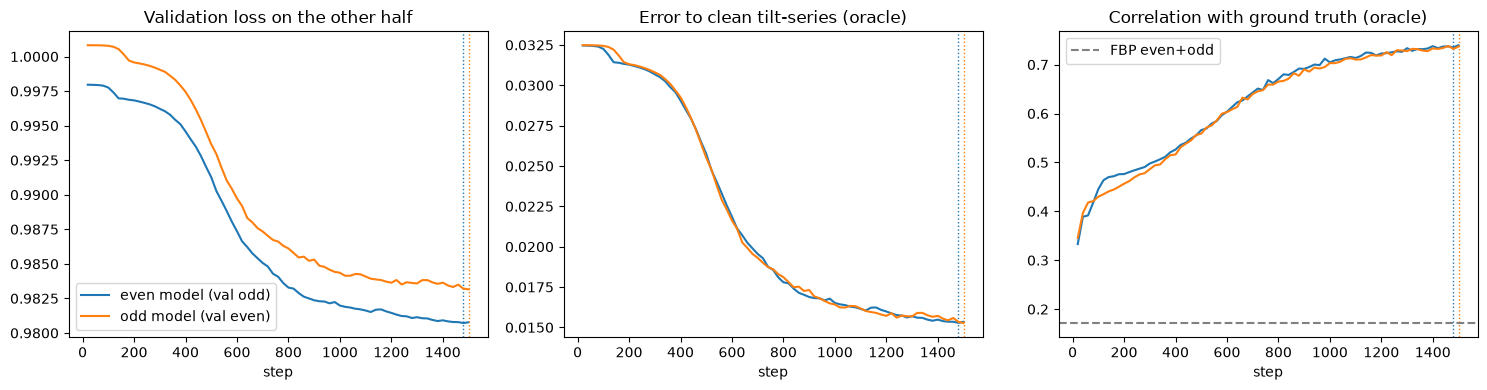

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for name, history, best_step, color in [
    ("even model (val odd)", even_history, even_step, "C0"),
    ("odd model (val even)", odd_history, odd_step, "C1"),
]:
    axes[0].plot(history["step"], history["val"], color=color, label=name)
    axes[1].plot(history["step"], history["clean"], color=color)
    axes[2].plot(history["step"], history["cc"], color=color)
    for ax in axes:
        ax.axvline(best_step, color=color, ls=":", lw=1)  # best checkpoint
axes[0].set_title("Validation loss on the other half")
axes[0].legend()
axes[1].set_title("Error to clean tilt-series (oracle)")
axes[2].axhline(correlation(fbp_full, ground_truth), color="gray", ls="--", label="FBP even+odd")
axes[2].set_title("Correlation with ground truth (oracle)")
axes[2].legend()
for ax in axes:
    ax.set_xlabel("step")
plt.tight_layout()
plt.show()

## Combine the halves

* **Average**: independent noise in the two maps drops by $\sqrt{2}$.
* **Noise estimate**: $(f_{even} - f_{odd})/2$ contains no signal, only what the networks fitted independently.
* **Half-map FSC**: optimistic here, because both halves share the same priors (positivity, TV), which correlate
  them beyond the real signal. Compare with the FSC against the ground truth below.

In [12]:
average = (even_inr + odd_inr) / 2
noise_estimate = (even_inr - odd_inr) / 2

half_map_fsc = fourier_shell_correlation(even_inr, odd_inr)
below = (half_map_fsc[1:] < 0.143).nonzero()
if len(below):
    print(f"half-map FSC crosses 0.143 at {1 / shell_frequency[1:][below[0, 0]]:.1f} A (optimistic, see above)\n")
else:
    print("half-map FSC stays above 0.143 up to Nyquist (optimistic, see above)\n")

band = (shell_frequency > 0.005) & (shell_frequency <= 0.04)  # up to the first CTF zero
print(f"{'':<14} {'cc':>6} {'cc 8A-lp':>9} {'bg/particle':>12} {'FSC measured':>13} {'FSC wedge':>10}   (mean FSC 0.005-0.04 1/A)")
for name, volume in [("even INR", even_inr), ("odd INR", odd_inr), ("average", average), ("FBP even+odd", fbp_full)]:
    measured = fsc(volume, region=~in_wedge)[band].mean()
    wedge = fsc(volume, region=in_wedge)[band].nanmean()
    print(
        f"{name:<14} {correlation(volume, ground_truth):6.3f} {correlation(volume, truth_lowpass):9.3f} "
        f"{background_ratio(volume):12.3f} {measured:13.3f} {wedge:10.3f}"
    )

half-map FSC crosses 0.143 at 18.5 A (optimistic, see above)

                   cc  cc 8A-lp  bg/particle  FSC measured  FSC wedge   (mean FSC 0.005-0.04 1/A)


even INR        0.735     0.941        0.137         0.759      0.380
odd INR         0.737     0.940        0.130         0.754      0.373


average         0.740     0.945        0.132         0.790      0.399


FBP even+odd    0.172     0.130        0.734         0.631      0.033


## Visual comparison

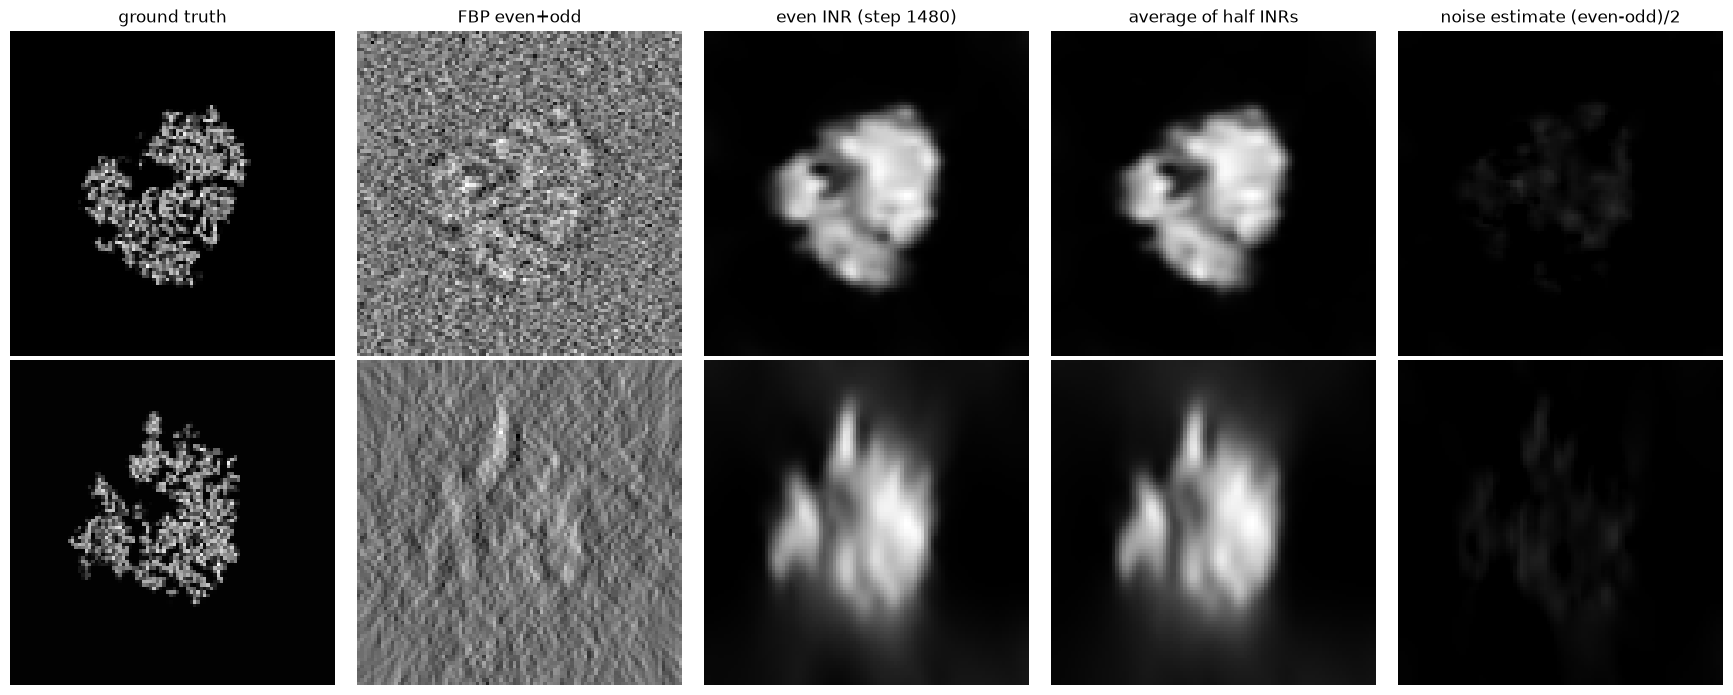

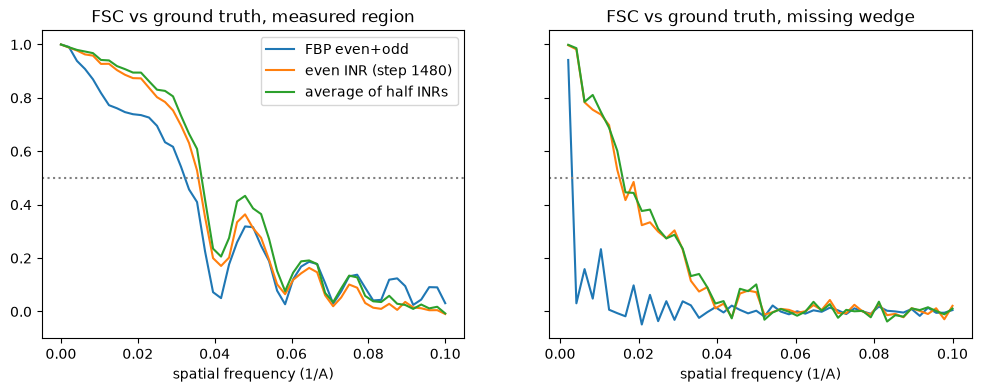

In [13]:
volumes = {
    "ground truth": ground_truth,
    "FBP even+odd": fbp_full,
    f"even INR (step {even_step})": even_inr,
    "average of half INRs": average,
    "noise estimate (even-odd)/2": noise_estimate,
}
fig, axes = plt.subplots(2, len(volumes), figsize=(3.5 * len(volumes), 7))
for col, (name, volume) in enumerate(volumes.items()):
    # the noise estimate shares the colour scale of the average, so its amplitude can be compared
    limits = {"vmin": average.min(), "vmax": average.max()} if name.startswith("noise") else {}
    axes[0, col].imshow(volume[BOX // 2], cmap="gray", **limits)  # central z-slice
    axes[0, col].set_title(name)
    axes[1, col].imshow(volume[:, BOX // 2], cmap="gray", **limits)  # central y-slice (x-z plane), shows the wedge
    for ax in axes[:, col]:
        ax.set_axis_off()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for name in ["FBP even+odd", f"even INR (step {even_step})", "average of half INRs"]:
    axes[0].plot(shell_frequency, fsc(volumes[name], region=~in_wedge), label=name)
    axes[1].plot(shell_frequency, fsc(volumes[name], region=in_wedge), label=name)
axes[0].set_title("FSC vs ground truth, measured region")
axes[1].set_title("FSC vs ground truth, missing wedge")
for ax in axes:
    ax.axhline(0.5, color="gray", ls=":")
    ax.set_xlabel("spatial frequency (1/A)")
axes[0].legend()
plt.show()

## Comparison with Gaussian-smoothed FBP

Is the INR better than simply smoothing the FBP of $(y_{even} + y_{odd})/2$? The FBP is smoothed with Gaussians of
increasing width. Note that an isotropic filter only reweights whole shells, so the FSC per shell of the smoothed
FBP is the same as that of the raw FBP: smoothing improves the CC and the background, but cannot fill the wedge or
recover information. The best sigma is picked with the ground truth, which favours the FBP baseline.

                           cc  cc 8A-lp  bg/particle
FBP sigma 10 A          0.498     0.568        0.299
FBP sigma 20 A          0.599     0.772        0.298
FBP sigma 30 A          0.609     0.805        0.310
INR average             0.740     0.945        0.132


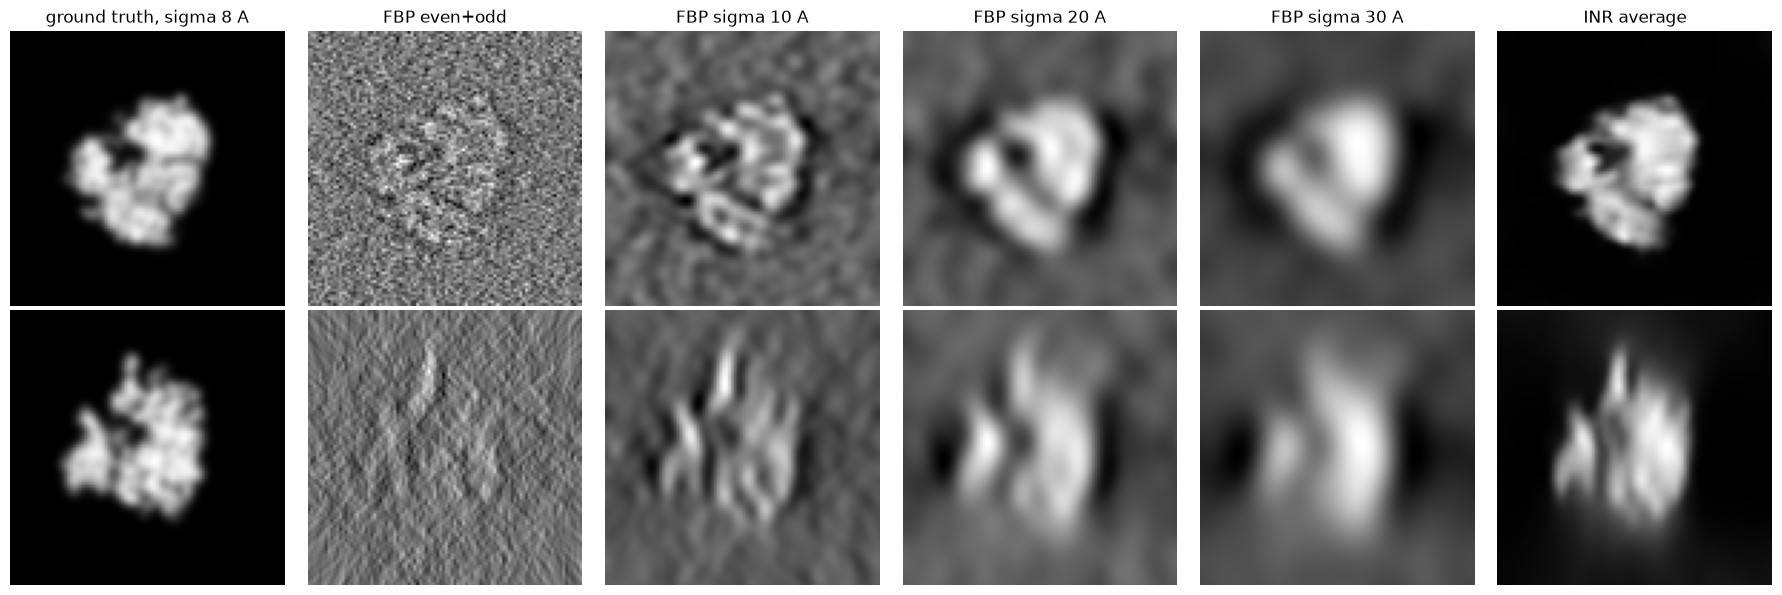

In [14]:
sigmas = [10.0, 20.0, 30.0]  # A
fbp_smoothed = {sigma: gaussian_lowpass(fbp_full, sigma) for sigma in sigmas}

print(f"{'':<22} {'cc':>6} {'cc 8A-lp':>9} {'bg/particle':>12}")
for name, volume in [(f"FBP sigma {s:g} A", v) for s, v in fbp_smoothed.items()] + [("INR average", average)]:
    print(f"{name:<22} {correlation(volume, ground_truth):6.3f} {correlation(volume, truth_lowpass):9.3f} {background_ratio(volume):12.3f}")

panels = {"ground truth, sigma 8 A": truth_lowpass, "FBP even+odd": fbp_full}
panels.update({f"FBP sigma {s:g} A": v for s, v in fbp_smoothed.items()})
panels["INR average"] = average
fig, axes = plt.subplots(2, len(panels), figsize=(3 * len(panels), 6))
for col, (name, volume) in enumerate(panels.items()):
    axes[0, col].imshow(volume[BOX // 2], cmap="gray")  # central z-slice
    axes[0, col].set_title(name)
    axes[1, col].imshow(volume[:, BOX // 2], cmap="gray")  # central y-slice (x-z plane), shows the wedge
    for ax in axes[:, col]:
        ax.set_axis_off()
plt.tight_layout()
plt.show()

## Save the reconstructions

In [15]:
for name, volume in [("even", even_inr), ("odd", odd_inr), ("average", average)]:
    with mrcfile.new(DATA / f"ribosome_inr_{name}.mrc", overwrite=True) as mrc:
        mrc.set_data(volume.numpy().astype(np.float32))
        mrc.voxel_size = PIXEL_SPACING

## Notes: design decisions and still to do

Key variants, single INR on the even half validated on odd, lr 1e-4, 1000 steps (mean FSC over 0.005-0.04 1/A):

| variant | val loss | cc | cc 8A-lp | bg/particle | FSC measured | FSC wedge |
|---|---|---|---|---|---|---|
| no CTF, no positivity, TV on the feature grids | 0.9873 | 0.468 | | 0.458 | 0.475 | -0.029 |
| CTF + positivity, TV on the feature grids | 0.9889 | 0.559 | | 0.435 | 0.517 | 0.052 |
| CTF + positivity + first-order TV 3 | **0.9787** | **0.737** | 0.90 | **0.154** | **0.755** | **0.383** |
| CTF + positivity + second-order TV 3 (current) | 0.9812 | 0.720 | **0.92** | 0.174 | 0.725 | 0.316 |

* **Encoding**: global Fourier features fitted noise as ripples across the whole box; the local multi-resolution
  grid does not. Finer grid levels (64, 96) fit noise sooner and were worse; dropping the 48-cell level (or also the
  32) loses the detail in the second CTF lobe (0.046-0.054 1/A), while 2 instead of 4 features per node halves the
  parameters at nearly the same validation loss and FSC.
* **Grid artefacts**: trilinear interpolation kinks at identical grid positions in both halves inflated the half-map
  FSC at high frequency; random per-model grid offsets fixed this, smoothstep interpolation reduced the remaining
  correlation near Nyquist. Jittering the ray position within the pixel had no effect and was dropped. The fine
  z-elongated stripes that remain are fitted noise, independent between the halves.
* **CTF + positivity**: positivity only holds for the actual potential, so it requires the CTF in the forward model.
  Together with a TV prior on the density it partly fills the missing wedge.
* **TV weight**: the lowest validation loss on the other half also gave the best ground-truth metrics, so the weight
  can be chosen without ground truth. Second-order TV sweep (0.3, 1, 3, 10, 30): 3 is best; lower weights overfit
  sooner, higher weights wash out the particle.
* **First- vs second-order TV**: first-order TV scores slightly better in the 25-200 A band and in the wedge, but
  gives flat plateaus with hard edges; second-order TV is closer to the low-passed truth. The phantom (potential in
  vacuum, hard zero background) favours first-order TV; real particles in ice have softer boundaries.
* **Learning rate**: at 5e-4 the CTF models overfit within ~100 steps; 1e-4 is used.
* **Training length**: automatic early stopping on the other half stopped too early (the validation loss keeps
  improving slowly while the background is cleaned) and a threshold tuned here would not transfer to experimental
  data. Cosine annealing to zero at 1500 steps halves the average learning rate and was clearly worse than a constant
  learning rate.
* **Even/odd use**: random swapping between the halves converges to fitting their average, noise included, and leaves
  nothing for validation. Averaging and an FSC filter based on the half-map FSC: the filter changed nothing
  measurable, and the half-map FSC is inflated by the shared priors.

* **Box edges**: density rises towards the box faces, mostly as streaks along z. The tilt visibility map ruled out
  the field of view as the main cause (80% of the box, a disc in x-z, is seen by all tilts; only the corners by
  fewer): smooth structure along z lies in the missing wedge, and second-order TV does not penalise ramps. TV was
  extended to the box faces (it previously skipped the outer voxel layer).

Still to do:
* Constrain the density to a z-slab of known thickness (lamella / ice layer), which targets the z streaks and is
  physical for experimental data.
* Pad the rendered images before the CTF multiplication to avoid periodic wrap-around (the simulation is periodic,
  so it is consistent here, but experimental data are not).
* Re-check the second-order TV weight (e.g. 2 and 5) and the learning rate at 3000 steps.
* Phase-randomisation test (randomise the phases beyond ~0.04 1/A in the tilt images of each half independently,
  reconstruct, and correct the half-map FSC) to quantify how much the priors inflate the half-map FSC.